In [98]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures

In [99]:
X, y = make_circles(n_samples=10000, noise=0.1, random_state=42)

print(X.shape, y.shape)

poly = PolynomialFeatures(degree=6, include_bias=False)

X = poly.fit_transform(X)

print(X.shape, y.shape)

(10000, 2) (10000,)
(10000, 27) (10000,)


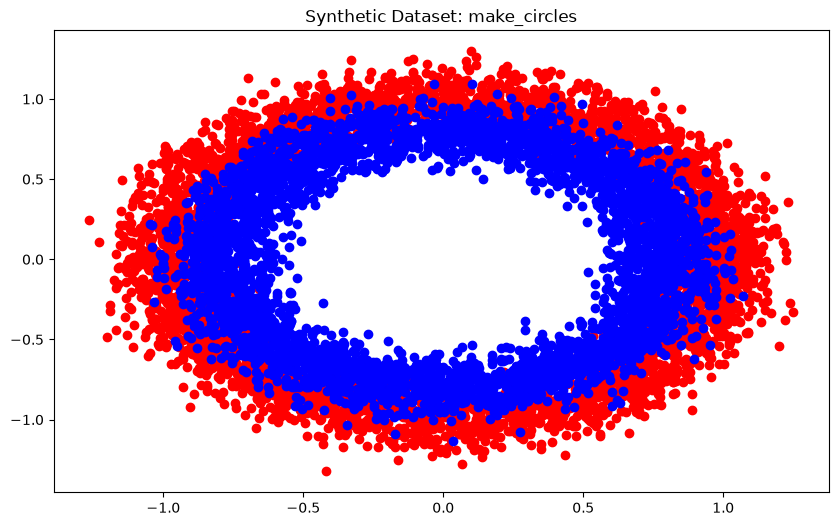

In [100]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
plt.figure(figsize=(10, 6))
plt.scatter(X_train[y_train==0][:, 0], X_train[y_train==0][:, 1], color='red', label='Class 0')
plt.scatter(X_train[y_train==1][:, 0], X_train[y_train==1][:, 1], color='blue', label='Class 1')
plt.title('Synthetic Dataset: make_circles')
plt.show()

In [101]:
def sigmoid(z):
    return 1/ (1 + np.exp(-z))

In [102]:
def compute_cost(X, y, w, b, Lambda_):
    m = X.shape[0]

    z = np.dot(X, w) + b
    h = sigmoid(z)

    loss  = -y * np.log(h) - (1 - y) * np.log(1 - h)
    cost = np.sum(loss) / m


    reg_cost = (Lambda_ / (2 * m) * np.sum(np.square(w)))
    total_cost = cost + reg_cost

    return total_cost

In [103]:
def compute_gradient(X, y, w, b, Lambda_):
    m = X.shape[0]
    n = X.shape[1]

    z = np.dot(X, w) + b
    h = sigmoid(z)

    dJ_dw = np.zeros(w.shape)
    dJ_db = 0

    dJ_dw = np.dot(X.T, h - y)
    dJ_db = np.sum(h - y)

    #Runs a lot slower than the vectorized version above, but is easier to understand
    #for i in range(m):
    #    dJ_db += (h[i] - y[i])
    #    for j in range(n):
    #        dJ_dw[j] += (h[i] - y[i]) * X[i][j]

    dJ_dw = dJ_dw / m
    dJ_db = dJ_db / m

    dJ_dw += (Lambda_ / m) * w

    return dJ_dw, dJ_db

In [104]:
def gradient_descent(X, y, w_in, b_in, alpha, num_iters, Lambda_):
    J_history = []

    w = w_in.copy()
    b = b_in

    for i in range(num_iters):
        dJ_dw, dJ_db = compute_gradient(X, y, w, b, Lambda_)

        w = w - alpha * dJ_dw
        b = b - alpha * dJ_db

        if i % 100 == 0:
            cost = compute_cost(X, y, w, b, Lambda_)
            J_history.append(cost)
            print(f"Iteration {i}: Cost {cost}")

    return w, b, J_history

In [117]:
w = np.zeros(X_train.shape[1])
b = 0
alpha = 1
Lambda_ = .01
num_iters = 100000

w, b, J_history = gradient_descent(X_train, y_train, w, b, alpha, num_iters, Lambda_)

Iteration 0: Cost 0.675289433316884
Iteration 100: Cost 0.4262789685908547
Iteration 200: Cost 0.39722003029379166
Iteration 300: Cost 0.3854489864862579
Iteration 400: Cost 0.3787741267209371
Iteration 500: Cost 0.37441359072573493
Iteration 600: Cost 0.3713676955884599
Iteration 700: Cost 0.36916262635686165
Iteration 800: Cost 0.36753069578279424
Iteration 900: Cost 0.3663039154326712
Iteration 1000: Cost 0.36537021788073165
Iteration 1100: Cost 0.36465203494087395
Iteration 1200: Cost 0.36409436107118737
Iteration 1300: Cost 0.3636574963322157
Iteration 1400: Cost 0.3633123836832761
Iteration 1500: Cost 0.36303750460864487
Iteration 1600: Cost 0.36281676063944623
Iteration 1700: Cost 0.3626380002491835
Iteration 1800: Cost 0.3624919785154223
Iteration 1900: Cost 0.36237161245319005
Iteration 2000: Cost 0.36227144154775404
Iteration 2100: Cost 0.3621872326821008
Iteration 2200: Cost 0.3621156879530035
Iteration 2300: Cost 0.3620542266458708
Iteration 2400: Cost 0.36200082122646365
I

Text(0, 0.5, 'Cost')

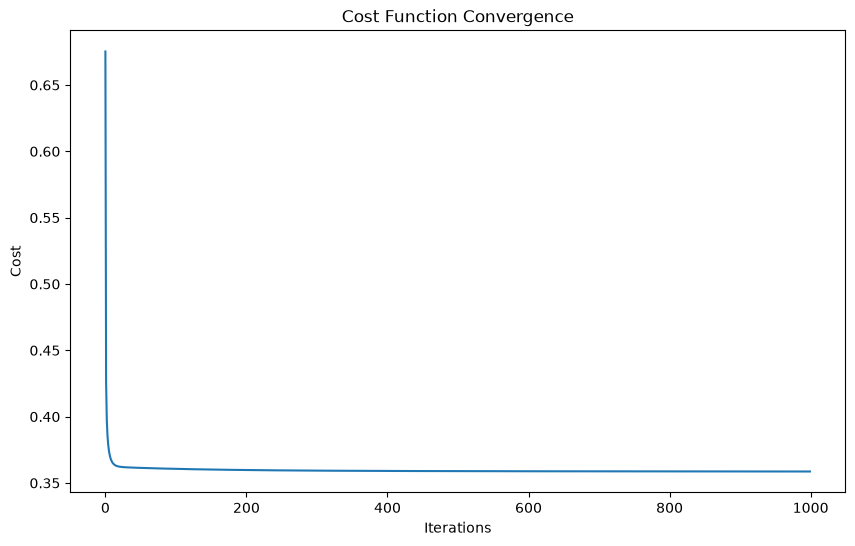

In [118]:
plt.figure(figsize=(10, 6))
plt.plot(J_history)
plt.title('Cost Function Convergence')
plt.xlabel('Iterations')
plt.ylabel('Cost')

In [119]:
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score, f1_score

y_pred = sigmoid(np.dot(X_test, w) + b)

print("Accuracy:", accuracy_score(y_test, y_pred >= 0.5))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred >= 0.5))
print("Recall:", recall_score(y_test, y_pred >= 0.5))
print("Precision:", precision_score(y_test, y_pred >= 0.5))
print("F1 Score:", f1_score(y_test, y_pred >= 0.5))
print("Final Weights:", w)
print("Final Bias:", b)

Accuracy: 0.831
Confusion Matrix:
 [[826 187]
 [151 836]]
Recall: 0.8470111448834853
Precision: 0.8172043010752689
F1 Score: 0.8318407960199005
Final Weights: [  0.4490924    0.1900793  -10.58257705   0.39837826  -9.63749875
  -1.06579876   0.85741594  -0.46844927  -0.40688475  -2.4831846
   1.16666396  -1.90280114  -2.72691576  -4.12484987   0.62805174
  -1.49084292   0.39502121  -0.31691305  -0.23373922   0.1783164
   1.97933526  -1.56010774   0.58991529   0.33484764   2.9513653
   2.15135479   2.62199658]
Final Bias: 9.224547502046397
